<a href="https://colab.research.google.com/github/Harsha192525108/MLA0204_HARSHA_192525108/blob/main/Practicals/practical-10/practical-10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Credit Score Dataset:
     Income      Debt  Payment_History  Credit_Utilization  Loan_Count  \
0  3.143524  0.660636         3.750192            2.264068   -1.672582   
1  1.214258  3.527593        -0.307126           -1.223554    1.877181   
2 -2.084283 -0.776735         1.482748            2.193310   -1.451970   
3  1.182606  1.551034        -0.933242            0.342521   -1.700943   
4 -3.051684 -3.316042         0.610564            0.899818   -2.974384   

   Account_Age  Credit_Score  
0    -0.480648             0  
1     1.447796             1  
2     0.820232             2  
3     0.739675             0  
4    -0.592241             2  

Credit Score Classification Accuracy:
99.5 %

Confusion Matrix:
[[67  0  0]
 [ 0 67  0]
 [ 1  0 65]]

Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      0.99        67
           1       1.00      1.00      1.00        67
           2       1.00      0.98      0.99        66

   

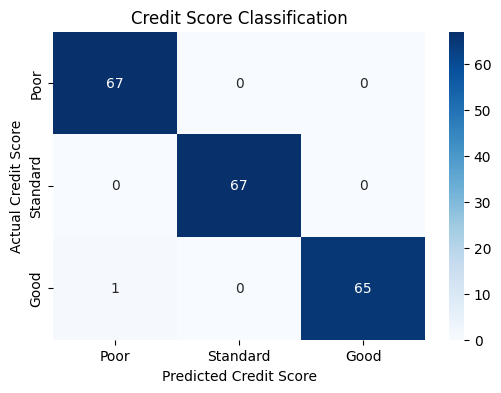


New Customer Credit Score:
Standard


In [1]:

# Credit Score Classification Using Random Forest

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.metrics import classification_report

# Step 1: Generate a sample credit score dataset
X, y = make_classification(
    n_samples=1000,
    n_features=6,
    n_informative=5,
    n_redundant=0,
    n_classes=3,
    n_clusters_per_class=1,
    class_sep=1.5,
    random_state=42
)

# Step 2: Create a DataFrame
df = pd.DataFrame(X, columns=[
    'Income',
    'Debt',
    'Payment_History',
    'Credit_Utilization',
    'Loan_Count',
    'Account_Age'
])

# Assign credit score categories
df['Credit_Score'] = y

print("Credit Score Dataset:")
print(df.head())

# Step 3: Separate input and output
X = df.drop('Credit_Score', axis=1)
y = df['Credit_Score']

# Step 4: Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Step 5: Create and train the model
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

# Step 6: Predict credit score
y_pred = model.predict(X_test)

# Step 7: Display accuracy
accuracy = accuracy_score(y_test, y_pred)

print("\nCredit Score Classification Accuracy:")
print(accuracy * 100, "%")

# Step 8: Display confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)

# Step 9: Display classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Step 10: Visualize confusion matrix
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Poor', 'Standard', 'Good'],
    yticklabels=['Poor', 'Standard', 'Good']
)

plt.xlabel("Predicted Credit Score")
plt.ylabel("Actual Credit Score")
plt.title("Credit Score Classification")
plt.show()

# Step 11: Predict a new customer's credit score
new_customer = pd.DataFrame(
    [[0.5, -0.3, 1.2, -0.5, 0.8, 1.0]],
    columns=X.columns
)

prediction = model.predict(new_customer)

score_labels = {
    0: 'Poor',
    1: 'Standard',
    2: 'Good'
}

print("\nNew Customer Credit Score:")
print(score_labels[prediction[0]])
